# INSTRODUCTION

Skin lesions represent a broad range of dermatological conditions, including benign lesions and malignant skin cancers. Accurate classification of these lesions is important for appropriate clinical assessment and patient management. However, interpreting skin lesions can be challenging because different conditions may share similar visual characteristics.

Deep learning, particularly convolutional neural networks (CNNs), has demonstrated potential for automated image classification by learning discriminative features directly from images. These techniques may support the development of computer-assisted systems for classifying skin lesions.

This project uses the publicly available HAM10000 dataset to investigate the application of deep learning to the classification of dermatoscopic skin lesion images across seven diagnostic categories. The project will involve data inspection, exploratory analysis, image preprocessing, model development, and performance evaluation.

The model will be evaluated using overall and class-specific performance measures, including precision, recall, F1-score, and a confusion matrix. Particular attention will be paid to class imbalance and the possibility of data leakage arising from multiple images associated with the same lesion.

The findings will be interpreted within the limitations of the dataset. The resulting model will be considered an experimental classification system rather than a substitute for professional dermatological assessment.

# **2.1 DATA AQUISATION**

### 2.1 Data Acquisition

**Dataset title:** Skin Disease Dataset

**Source platform:** Kaggle

**Dataset publisher:** subirbiswas19

**Dataset URL:** https://www.kaggle.com/datasets/subirbiswas19/skin-disease-dataset

**Data type:** Labelled skin-disease images for supervised image classification.

**Dataset structure:** The downloaded archive contains separate training and testing directories, with disease categories represented by subdirectories.

**Dataset size:** The initial inspection identified 1,159 image files, comprising 925 training images and 234 testing images.

**Target variable:** The disease category represented by each image's directory name.

**Prediction objective:** To develop a machine-learning model capable of classifying input skin images into the eight disease categories represented in the dataset.

**Planned preparation:** The images will be inspected for duplicate files, unreadable images, inconsistent formats, image dimensions, and class imbalance. The existing train-test separation will also be reviewed to prevent data leakage.

**Source verification and licensing:** The dataset was downloaded from Kaggle. Its original image provenance, license, and permitted-use conditions must be confirmed from the dataset documentation before finalising the project.

**Reference**

subirbiswas19. (n.d.). *Skin Disease Dataset* [Data set]. Kaggle. https://www.kaggle.com/datasets/subirbiswas19/skin-disease-dataset

# **Importing neccesary librabry**

In [ ]:

# ASSISTED BY CHATCGPT AI AND GEMINI
# SKIN DISEASE PREDICTION CAPSTONE PROJECT
# Stage 1: Environment Setup and Library Imports

# 1. Operating system and file management
import os
import shutil
import zipfile
import hashlib
from pathlib import Path
from collections import Counter

# 2. Data manipulation and numerical computing
import pandas as pd
import numpy as np

# 3. Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# 4. Image processing
from PIL import Image, UnidentifiedImageError

# 5. Machine learning and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# 6. Deep learning: TensorFlow and Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# 7. Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

sns.set_theme(style="whitegrid")

# 8. Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# 9. Confirm environment
print("All required libraries imported successfully.")
print("Python environment: Google Colab")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)


All required libraries imported successfully.
Python environment: Google Colab
Pandas version: 2.2.3
NumPy version: 2.1.3
TensorFlow version: 2.21.0
GPU available: True


**for the line of code below let us confirm our available hardware**

In [ ]:
# ASSISTED BY GEMINI
# Check available hardware
print("TensorFlow devices:")

for device in tf.config.list_physical_devices():
    print(device)

# Check GPU details if a GPU is available
!nvidia-smi


TensorFlow devices:
PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
Mon Oct 12 22:07:08 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8              9W /   70W |       3MiB /  15360MiB |      0%      

# 2.2 DATA LOADING AND CLEANING

In [9]:

# Upload the ZIP file into Google Colab
# ASSISTED BY CHATCGPT AI AND GEMINI
from google.colab import files
from pathlib import Path
import zipfile
import os

uploaded = files.upload()

zip_files = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]

if not zip_files:
    raise ValueError("Please upload your skin disease dataset ZIP file.")

zip_path = zip_files[0]
extract_dir = "/content/skin_disease_dataset"

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as archive:
    # Check archive paths before extracting
    for member in archive.namelist():
        target = (Path(extract_dir) / member).resolve()
        if not target.is_relative_to(Path(extract_dir).resolve()):
            raise ValueError("Unsafe path detected in ZIP archive.")
    archive.extractall(extract_dir)

print("Dataset extracted successfully.")
print("Location:", extract_dir)


Saving archive (4).zip to archive (4).zip
Dataset extracted successfully.
Location: /content/skin_disease_dataset


# **Here we wil be Inspecting the directory structure and image counts**
This cell identifies the image files and summarizes the disease folders and dataset splits.

In [10]:
# ASSISTED BY CHATCGPT AI AND GEMINI
import pandas as pd
from pathlib import Path

# Fallback definition for extract_dir if it is not in the environment
if 'extract_dir' not in globals():
    extract_dir = "/content/skin_disease_dataset"

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

image_records = []

for path in Path(extract_dir).rglob("*"):
    if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
        continue

    parts = path.parts

    split = next(
        (part for part in parts
         if part.lower() in {"train_set", "test_set", "train", "test"}),
        "unknown"
    )

    image_records.append({
        "path": str(path),
        "filename": path.name,
        "extension": path.suffix.lower(),
        "split": split,
        "disease": path.parent.name
    })

df = pd.DataFrame(image_records)

if df.empty:
    raise ValueError(
        "No images found. Inspect the extracted folders and adjust "
        "IMAGE_EXTENSIONS or the extraction path."
    )

print("Total images:", len(df))
print("\nImages by split:")
print(df["split"].value_counts())

print("\nImages per disease and split:")
display(pd.crosstab(df["disease"], df["split"]))

print("\nFile formats:")
display(df["extension"].value_counts().rename("count").to_frame())

print("\nFirst five image records:")
display(df.head())

Total images: 1159

Images by split:
split
train_set    925
test_set     234
Name: count, dtype: int64

Images per disease and split:


split,test_set,train_set
disease,,
BA- cellulitis,34,136
BA-impetigo,20,80
FU-athlete-foot,32,124
FU-nail-fungus,33,129
FU-ringworm,23,90
PA-cutaneous-larva-migrans,25,100
VI-chickenpox,34,136
VI-shingles,33,130



File formats:


,count
extension,
.jpg,1031
.jpeg,106
.png,20
.webp,2



First five image records:


,path,filename,extension,split,disease
0,/content/skin_disease_dataset/skin-disease-dat...,40_BA-impetigo (66).jpg,.jpg,train_set,BA-impetigo
1,/content/skin_disease_dataset/skin-disease-dat...,15_BA-impetigo (38).jpg,.jpg,train_set,BA-impetigo
2,/content/skin_disease_dataset/skin-disease-dat...,66_BA-impetigo (1).jpg,.jpg,train_set,BA-impetigo
3,/content/skin_disease_dataset/skin-disease-dat...,56_BA-impetigo (3).jpg,.jpg,train_set,BA-impetigo
4,/content/skin_disease_dataset/skin-disease-dat...,72_BA-impetigo (85).jpg,.jpg,train_set,BA-impetigo


This audit and inspection above  establishes the number of image files, their folder-derived class labels, the distribution between training and testing sets, and the image formats present. These results will be compared with the dataset description prepared in Stage 2.1. Any discrepancies will be investigated before cleaning.

# **checking our image intergrity and dimention**

In [ ]:

from PIL import Image, UnidentifiedImageError

image_info = []
corrupted = []

for path in df["path"]:
    try:
        with Image.open(path) as img:
            img.verify()

        # Reopen the file after verification
        with Image.open(path) as img:
            image_info.append({
                "path": path,
                "width": img.width,
                "height": img.height,
                "mode": img.mode
            })

    except (UnidentifiedImageError, OSError, ValueError) as error:
        corrupted.append({
            "path": path,
            "error": str(error)
        })

image_info_df = pd.DataFrame(image_info)
corrupted_df = pd.DataFrame(corrupted)

print("Readable images:", len(image_info_df))
print("Unreadable images:", len(corrupted_df))

if not image_info_df.empty:
    print("\nImage dimensions:")
    display(
        image_info_df[["width", "height"]]
        .describe()
        .round(2)
    )

    print("\nImage colour modes:")
    display(image_info_df["mode"].value_counts().to_frame("count"))

if not corrupted_df.empty:
    print("\nUnreadable image files:")
    display(corrupted_df.head(20))


Readable images: 1159
Unreadable images: 0

Image dimensions:


,width,height
count,1159.00,1159.00
mean,210.53,210.53
std,36.59,36.59
min,128.00,128.00
25%,209.00,209.00
50%,224.00,224.00
75%,224.00,224.00
max,268.00,268.00



Image colour modes:


,count
mode,
RGB,1159


Our Cleaning rule: We will only exclude images confirmed to be unreadable. Different image dimensions or colour modes are not automatically errors; they can be handled during preprocessing.

# Checking for duplicate image

In [ ]:

import hashlib

def calculate_sha256(path):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()

df["sha256"] = df["path"].apply(calculate_sha256)

duplicate_rows = df[
    df.duplicated(subset="sha256", keep=False)
].sort_values("sha256")

print(
    "Number of distinct duplicate groups:",
    duplicate_rows["sha256"].nunique()
)

print(
    "Total files belonging to duplicate groups:",
    len(duplicate_rows)
)

if not duplicate_rows.empty:
    display(
        duplicate_rows[
            ["filename", "disease", "split", "sha256", "path"]
        ]
    )

# Find duplicate content occurring across different splits
cross_split_hashes = (
    df.groupby("sha256")["split"]
      .nunique()
      .loc[lambda x: x > 1]
      .index
)

cross_split_duplicates = df[
    df["sha256"].isin(cross_split_hashes)
].sort_values(["sha256", "split"])

print(
    "\nFiles in duplicate groups crossing dataset splits:",
    len(cross_split_duplicates)
)

if not cross_split_duplicates.empty:
    display(
        cross_split_duplicates[
            ["filename", "disease", "split", "sha256"]
        ]
    )


Number of distinct duplicate groups: 27
Total files belonging to duplicate groups: 57


,filename,disease,split,sha256,path
582,FU-athlete-foot (60).jpg,FU-athlete-foot,train_set,0995f0f56be5073405605f9495da34c69503dfc0ca35ae4c5ce5e66a675eb1e8,/content/skin_disease_dataset/skin-disease-datasaet/train_set/FU-athlete-foot/FU-athlete-foot (6...
592,FU-athlete-foot (5).jpg,FU-athlete-foot,train_set,0995f0f56be5073405605f9495da34c69503dfc0ca35ae4c5ce5e66a675eb1e8,/content/skin_disease_dataset/skin-disease-datasaet/train_set/FU-athlete-foot/FU-athlete-foot (5...
1133,BA- cellulitis (148).jpg,BA- cellulitis,test_set,0fb58cac4cdf512fe6049c16c96bab637cf43f12d2721ad601273a6612383412,/content/skin_disease_dataset/skin-disease-datasaet/test_set/BA- cellulitis/BA- cellulitis (148)...
783,BA- cellulitis (118).jpg,BA- cellulitis,train_set,0fb58cac4cdf512fe6049c16c96bab637cf43f12d2721ad601273a6612383412,/content/skin_disease_dataset/skin-disease-datasaet/train_set/BA- cellulitis/BA- cellulitis (118...
311,103_VI-chickenpox (20).jpg,VI-chickenpox,train_set,16cbcb995898a8257bb1922c2886877df24967fbff0b175fb2501d6db1fdac93,/content/skin_disease_dataset/skin-disease-datasaet/train_set/VI-chickenpox/103_VI-chickenpox (2...
1006,143_VI-chickenpox (20).jpg,VI-chickenpox,test_set,16cbcb995898a8257bb1922c2886877df24967fbff0b175fb2501d6db1fdac93,/content/skin_disease_dataset/skin-disease-datasaet/test_set/VI-chickenpox/143_VI-chickenpox (20...
812,BA- cellulitis (108).jpg,BA- cellulitis,train_set,17f9e42fdfb25707b44b8594f47321af1ed8c31c6258f4dc4e79b8824efcd341,/content/skin_disease_dataset/skin-disease-datasaet/train_set/BA- cellulitis/BA- cellulitis (108...
748,BA- cellulitis (103).jpg,BA- cellulitis,train_set,17f9e42fdfb25707b44b8594f47321af1ed8c31c6258f4dc4e79b8824efcd341,/content/skin_disease_dataset/skin-disease-datasaet/train_set/BA- cellulitis/BA- cellulitis (103...
678,FU-athlete-foot (26).jpg,FU-athlete-foot,train_set,24eaf0ead8f3b59db5e0d5e6138c6c064f3d7e288bfada6612fdd39e3a4d7b97,/content/skin_disease_dataset/skin-disease-datasaet/train_set/FU-athlete-foot/FU-athlete-foot (2...
674,FU-athlete-foot (35).jpg,FU-athlete-foot,train_set,24eaf0ead8f3b59db5e0d5e6138c6c064f3d7e288bfada6612fdd39e3a4d7b97,/content/skin_disease_dataset/skin-disease-datasaet/train_set/FU-athlete-foot/FU-athlete-foot (3...



Files in duplicate groups crossing dataset splits: 24


,filename,disease,split,sha256
1133,BA- cellulitis (148).jpg,BA- cellulitis,test_set,0fb58cac4cdf512fe6049c16c96bab637cf43f12d2721ad601273a6612383412
783,BA- cellulitis (118).jpg,BA- cellulitis,train_set,0fb58cac4cdf512fe6049c16c96bab637cf43f12d2721ad601273a6612383412
1006,143_VI-chickenpox (20).jpg,VI-chickenpox,test_set,16cbcb995898a8257bb1922c2886877df24967fbff0b175fb2501d6db1fdac93
311,103_VI-chickenpox (20).jpg,VI-chickenpox,train_set,16cbcb995898a8257bb1922c2886877df24967fbff0b175fb2501d6db1fdac93
936,5_PA-cutaneous-larva-migrans (31).jpg,PA-cutaneous-larva-migrans,test_set,27ab9d288e4f9efff3b64df39e16a85665a2d938d560faf86df7d493774fa9c9
89,20_PA-cutaneous-larva-migrans (31).jpg,PA-cutaneous-larva-migrans,train_set,27ab9d288e4f9efff3b64df39e16a85665a2d938d560faf86df7d493774fa9c9
1068,42_BA-impetigo (2).png,BA-impetigo,test_set,54a983a47fd40301978586d4d0176544b44708d9294dd705643b720246fba06e
529,79_BA-impetigo (2).png,BA-impetigo,train_set,54a983a47fd40301978586d4d0176544b44708d9294dd705643b720246fba06e
949,13_PA-cutaneous-larva-migrans (3).jpg,PA-cutaneous-larva-migrans,test_set,610657172da4ababa3f9d156afd16ab53ffd9561bd116f5540f9b5dd472442f7
58,27_PA-cutaneous-larva-migrans (3).jpg,PA-cutaneous-larva-migrans,train_set,610657172da4ababa3f9d156afd16ab53ffd9561bd116f5540f9b5dd472442f7


We should investigate the 27 duplicate groups before saving the final audit report or deleting any images.
our results mean:
- 27 distinct duplicate groups were detected.
- 57 files belong to those groups.
- If each group contains at least two files, there are 30 files beyond the first copy in each group (\(57-27=30\)).
However, we don't yet know how many duplicates occur across the training and testing sets, whether any duplicates have conflicting disease labels, or whether they are all safe to remove. Those checks will determine our cleaning decisions.

# Examining duplicate group

In [ ]:

# Summarize every exact-duplicate group
duplicate_summary = (
    df[df.duplicated(subset="sha256", keep=False)]
    .groupby("sha256")
    .agg(
        number_of_files=("path", "size"),
        disease_labels=("disease", lambda x: sorted(set(x))),
        dataset_splits=("split", lambda x: sorted(set(x))),
        filenames=("filename", list),
        paths=("path", list)
    )
    .reset_index()
)

duplicate_summary["crosses_splits"] = (
    duplicate_summary["dataset_splits"].apply(lambda x: len(x) > 1)
)

duplicate_summary["conflicting_labels"] = (
    duplicate_summary["disease_labels"].apply(lambda x: len(x) > 1)
)

print("Duplicate groups:", len(duplicate_summary))
print("Files in duplicate groups:",
      duplicate_summary["number_of_files"].sum())
print("Groups crossing train/test splits:",
      duplicate_summary["crosses_splits"].sum())
print("Groups with conflicting disease labels:",
      duplicate_summary["conflicting_labels"].sum())

display(
    duplicate_summary[
        ["number_of_files", "disease_labels", "dataset_splits",
         "crosses_splits", "conflicting_labels", "filenames"]
    ].sort_values(
        ["crosses_splits", "conflicting_labels"],
        ascending=False
    )
)


Duplicate groups: 27
Files in duplicate groups: 57
Groups crossing train/test splits: 11
Groups with conflicting disease labels: 0


,number_of_files,disease_labels,dataset_splits,crosses_splits,conflicting_labels,filenames
1,2,[BA- cellulitis],"[test_set, train_set]",True,False,"[BA- cellulitis (118).jpg, BA- cellulitis (148).jpg]"
2,2,[VI-chickenpox],"[test_set, train_set]",True,False,"[103_VI-chickenpox (20).jpg, 143_VI-chickenpox (20).jpg]"
5,2,[PA-cutaneous-larva-migrans],"[test_set, train_set]",True,False,"[20_PA-cutaneous-larva-migrans (31).jpg, 5_PA-cutaneous-larva-migrans (31).jpg]"
6,2,[BA-impetigo],"[test_set, train_set]",True,False,"[79_BA-impetigo (2).png, 42_BA-impetigo (2).png]"
7,2,[PA-cutaneous-larva-migrans],"[test_set, train_set]",True,False,"[27_PA-cutaneous-larva-migrans (3).jpg, 13_PA-cutaneous-larva-migrans (3).jpg]"
10,2,[VI-chickenpox],"[test_set, train_set]",True,False,"[141_VI-chickenpox (15).jpg, 56_VI-chickenpox (15).jpg]"
12,3,[VI-chickenpox],"[test_set, train_set]",True,False,"[132_VI-chickenpox (20).jpg, 81_VI-chickenpox (20).jpg, 14_VI-chickenpox (20).jpg]"
14,3,[VI-chickenpox],"[test_set, train_set]",True,False,"[72_VI-chickenpox (27).jpg, 10_VI-chickenpox (27).jpg, 12_VI-chickenpox (27).jpg]"
18,2,[PA-cutaneous-larva-migrans],"[test_set, train_set]",True,False,"[84_PA-cutaneous-larva-migrans (6).jpg, 86_PA-cutaneous-larva-migrans (6).jpg]"
19,2,[VI-shingles],"[test_set, train_set]",True,False,"[130_VI-shingles (4).jpg, 161_VI-shingles (4).jpg]"


The duplicate image analysis identified 27 groups of identical images, involving 57 files containing redundant copies. Of these, 11 duplicate groups were found across the training and testing sets, indicating a potential risk of data leakage that could affect the model’s evaluation performance. However, no conflicting disease labels were identified among the duplicate groups based on the folder labels examined.

The 27 groups contain 30 redundant copies beyond one retained file per group. However, we were careful here as the 11 cross-split groups needed to be handled so that identical images cannot appear in both the training and testing data used for final evaluation.

Because there are no conflicting labels, we don't currently have evidence that identical images were assigned different disease categories.

based on the nature of our study, we are deciding to follow the approach listed below:
1. Keep the original ZIP file unchanged as a backup.
2. Retain one representative image per exact-duplicate group in a separate working inventory.
3. Rebuild the training/testing split later, using stratified splitting where feasible, so duplicates cannot leak across the two sets.
4. Investigate near-duplicate images separately if necessary.
This is preferable to deleting 30 files blindly from the original folders. We'll preserve the original dataset and make our cleaning decisions reproducible.

# **Applying duplicate to our work inventory**

this line of code creates a deduplicated inventory; it does not delete any files from disk.

In [ ]:

# Create a deduplicated working inventory.
# The original images remain untouched.

df_original = df.copy()

# Confirm that every duplicate group has a single disease label.
label_check = (
    df_original.groupby("sha256")["disease"].nunique()
)

conflicting_hashes = label_check[label_check > 1].index

if len(conflicting_hashes) > 0:
    raise ValueError(
        "Conflicting labels detected. Review these groups before deduplication."
    )

# Keep one representative for each exact image hash.
# Sort first so the choice is reproducible.
df_working = (
    df_original.sort_values(["sha256", "path"])
    .drop_duplicates(subset="sha256", keep="first")
    .reset_index(drop=True)
)

print("Original image records:", len(df_original))
print("Unique image records:", len(df_working))
print("Redundant records excluded:", len(df_original) - len(df_working))

print("\nUnique images by disease:")
display(
    df_working.groupby("disease")
    .size()
    .sort_values(ascending=False)
    .rename("unique_images")
    .to_frame()
)

print("\nUnique images by original split:")
display(df_working["split"].value_counts().to_frame("unique_images"))


Original image records: 1159
Unique image records: 1129
Redundant records excluded: 30

Unique images by disease:


,unique_images
disease,
BA- cellulitis,168
FU-nail-fungus,162
VI-shingles,160
VI-chickenpox,158
FU-athlete-foot,153
PA-cutaneous-larva-migrans,118
FU-ringworm,111
BA-impetigo,99



Unique images by original split:


,unique_images
split,
train_set,897
test_set,232


Important: The original split column is retained only for auditing. Because we chose a representative by file path, this working inventory is not yet the final training/testing dataset. We'll create a new split after confirming the class counts and completing EDA.

# Saving our duplicate investigation and cleaning evidence

In [ ]:

# Save the duplicate investigation report
duplicate_report_path = "/content/duplicate_investigation_report.csv"

duplicate_summary.to_csv(duplicate_report_path, index=False)

# Save the working inventory for the next stages
working_inventory_path = "/content/skin_disease_deduplicated_inventory.csv"

df_working.to_csv(working_inventory_path, index=False)

print("Duplicate report:", duplicate_report_path)
print("Deduplicated inventory:", working_inventory_path)

files.download(duplicate_report_path)
files.download(working_inventory_path)


Duplicate report: /content/duplicate_investigation_report.csv
Deduplicated inventory: /content/skin_disease_deduplicated_inventory.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Duplicate Image Detection and Handling

Exact duplicate images were identified using SHA-256 file hashes. The initial audit detected 27 duplicate groups containing 57 image files, including 11 groups with images distributed across the original training and testing sets. No duplicate group contained conflicting disease labels.

The findings indicate a potential risk of data leakage, which could lead to overly optimistic evaluation results if identical images were retained across the training and testing sets. Therefore, one representative image was retained per unique file hash in the working inventory, while the original dataset was preserved unchanged.

The final training and testing sets will be established after further data inspection, using an appropriate stratified splitting procedure where feasible. This will ensure that exact duplicates do not occur across the final evaluation boundary. The duplicate investigation report and deduplicated inventory will be retained to support reproducibility.

befor we proceed let confirm our unique image count and number of images reamining in each class

In [ ]:
df_working = (
    df_original.sort_values(["sha256", "path"])
    .drop_duplicates(subset="sha256", keep="first")
    .reset_index(drop=True)
)

In [ ]:

# 1. Total number of unique images remaining
print("Total unique images remaining:", len(df_working))

# 2. Number of unique images in each disease class
class_counts = (
    df_working.groupby("disease")
    .size()
    .reset_index(name="unique_images_remaining")
    .sort_values("disease")
)

display(class_counts)


Total unique images remaining: 1129


,disease,unique_images_remaining
0,BA- cellulitis,168
1,BA-impetigo,99
2,FU-athlete-foot,153
3,FU-nail-fungus,162
4,FU-ringworm,111
5,PA-cutaneous-larva-migrans,118
6,VI-chickenpox,158
7,VI-shingles,160


our dataset now contains 1,129 unique images across 8 skin disease classes, compared with the original 1,159 image records. This means 30 redundant image records were excluded from your working inventory.

### **Data Cleaning: Identification and Removal of Duplicate Image Records**

Exact duplicate images were identified using the SHA-256 cryptographic hashing method. Images with identical hash values were treated as duplicate records, provided that their disease labels were consistent. The investigation identified 27 duplicate groups containing 57 image records, including 11 groups that appeared across the original training and testing splits. No conflicting disease labels were identified among the duplicate groups.

One representative image was retained from each duplicate group in the working inventory, excluding 30 redundant records. Following this procedure, the dataset contained **1,129 unique images distributed across eight skin disease classes**. The original dataset files were preserved, and duplicate exclusion was applied to the working inventory to reduce the risk of data leakage during subsequent model development.

Before model training, we going to  rebuild the training and testing splits using the deduplicated inventory. This is important because exact duplicates were found across the original splits.
Our next steps will be:
1. Visualize the number of images in each disease class.
2. Check image dimensions, colour modes, and any corrupted files.
3. Create a new stratified training, validation, and test split, where feasible.
4. Preprocess the images for model training.

# Checking image integrity and dimention

In [ ]:

# STEP 1: Check image integrity and dimensions

from PIL import Image, UnidentifiedImageError
import pandas as pd
from collections import Counter

image_results = []
corrupted_images = []

for _, row in df_working.iterrows():
    image_path = row["path"]

    try:
        with Image.open(image_path) as img:
            img.verify()

        # Reopen the image after verify() before reading its properties
        with Image.open(image_path) as img:
            image_results.append({
                "path": image_path,
                "disease": row["disease"],
                "width": img.width,
                "height": img.height,
                "format": img.format,
                "mode": img.mode
            })

    except (UnidentifiedImageError, OSError, ValueError) as error:
        corrupted_images.append({
            "path": image_path,
            "disease": row["disease"],
            "error": str(error)
        })

image_info_df = pd.DataFrame(image_results)
corrupted_df = pd.DataFrame(
    corrupted_images,
    columns=["path", "disease", "error"]
)

print("Images checked:", len(df_working))
print("Readable images:", len(image_info_df))
print("Unreadable/corrupted images:", len(corrupted_df))

print("\nImage formats:")
display(image_info_df["format"].value_counts().to_frame("count"))

print("\nImage colour modes:")
display(image_info_df["mode"].value_counts().to_frame("count"))

print("\nImage dimensions (width × height):")
display(
    image_info_df.groupby(["width", "height"])
    .size()
    .reset_index(name="number_of_images")
    .sort_values("number_of_images", ascending=False)
    .head(15)
)

if not corrupted_df.empty:
    print("\nImages requiring review:")
    display(corrupted_df)


Images checked: 1129
Readable images: 1129
Unreadable/corrupted images: 0

Image formats:


,count
format,
JPEG,1108
PNG,19
WEBP,2



Image colour modes:


,count
mode,
RGB,1129



Image dimensions (width × height):


,width,height,number_of_images
46,224,224,544
0,128,128,162
25,203,203,11
41,219,219,9
4,182,182,9
62,240,240,8
34,212,212,8
71,249,249,8
35,213,213,7
55,233,233,7


Our image-integrity check has produced a good result: all 1,129 unique images are readable, and none were flagged as corrupted. we are active (smiles)

# Data cleaning summary

### Image Integrity and Quality Checks

The 1,129 unique image records were examined for file readability, image format, colour mode, and dimensions. All 1,129 images were readable, and no corrupted or unreadable files were detected.

The dataset consisted of 1,108 JPEG images (98.1%), 19 PNG images (1.7%), and 2 WebP images (0.2%). All images were stored in RGB colour mode. Image dimensions varied, with 224 × 224 pixels being the most frequent resolution (544 images), followed by 128 × 128 pixels (162 images).

These findings indicate that the images are readable but have inconsistent dimensions. Therefore, the images will be resized to a uniform resolution during preprocessing to ensure compatibility with the selected deep learning models.

# 2.3 EXPLORATORY DATA ANALYSIS(EDA)

We will first, investigate the distribution of images across the eight disease classes. This will help us determine whether some classes are underrepresented, which could affect model performance.

# **Distribution of images across disease classes**

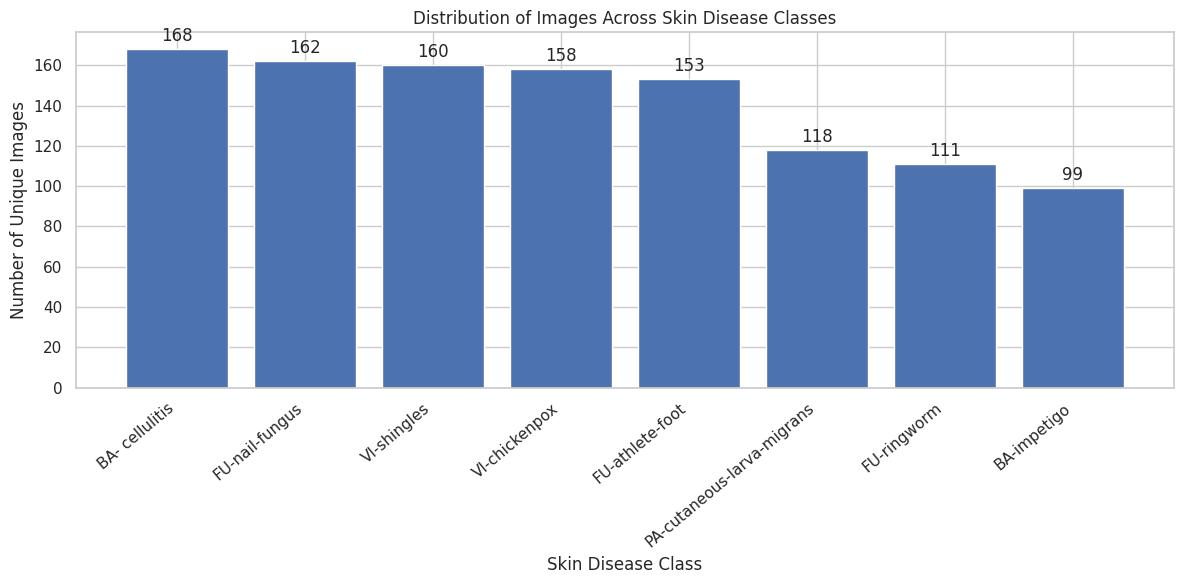

,Image_Count,Percentage
disease,,
BA- cellulitis,168,14.88
FU-nail-fungus,162,14.35
VI-shingles,160,14.17
VI-chickenpox,158,13.99
FU-athlete-foot,153,13.55
PA-cutaneous-larva-migrans,118,10.45
FU-ringworm,111,9.83
BA-impetigo,99,8.77


In [ ]:

# EDA 1: Distribution of images across disease classes

import matplotlib.pyplot as plt

class_counts = (
    df_working["disease"]
    .value_counts()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

bars = plt.bar(
    class_counts.index,
    class_counts.values
)

plt.title("Distribution of Images Across Skin Disease Classes")
plt.xlabel("Skin Disease Class")
plt.ylabel("Number of Unique Images")
plt.xticks(rotation=40, ha="right")

# Display the count above each bar
plt.bar_label(bars, padding=3)

plt.tight_layout()
plt.show()

# Display counts and percentages
class_distribution = pd.DataFrame({
    "Image_Count": class_counts,
    "Percentage": (class_counts / len(df_working) * 100).round(2)
})

display(class_distribution)


**### EDA 1: Distribution of Images Across Disease Classes**

The exploratory data analysis identified 1,129 unique images distributed across eight skin disease classes. Cellulitis was the most represented class, with 168 images (14.88%), followed by nail fungus with 162 images (14.35%) and shingles with 160 images (14.17%). Impetigo was the least represented class, with 99 images (8.77%).

The number of images per class ranged from 99 to 168, indicating some variation in class representation. Although the dataset is not perfectly balanced, all eight classes are represented. This variation may influence classification performance, so stratified data splitting and class-specific precision, recall, and F1-scores will be used to assess the models. Additional class-balancing techniques will be considered if evaluation results justify their use.

# **Visualization of our image sample**

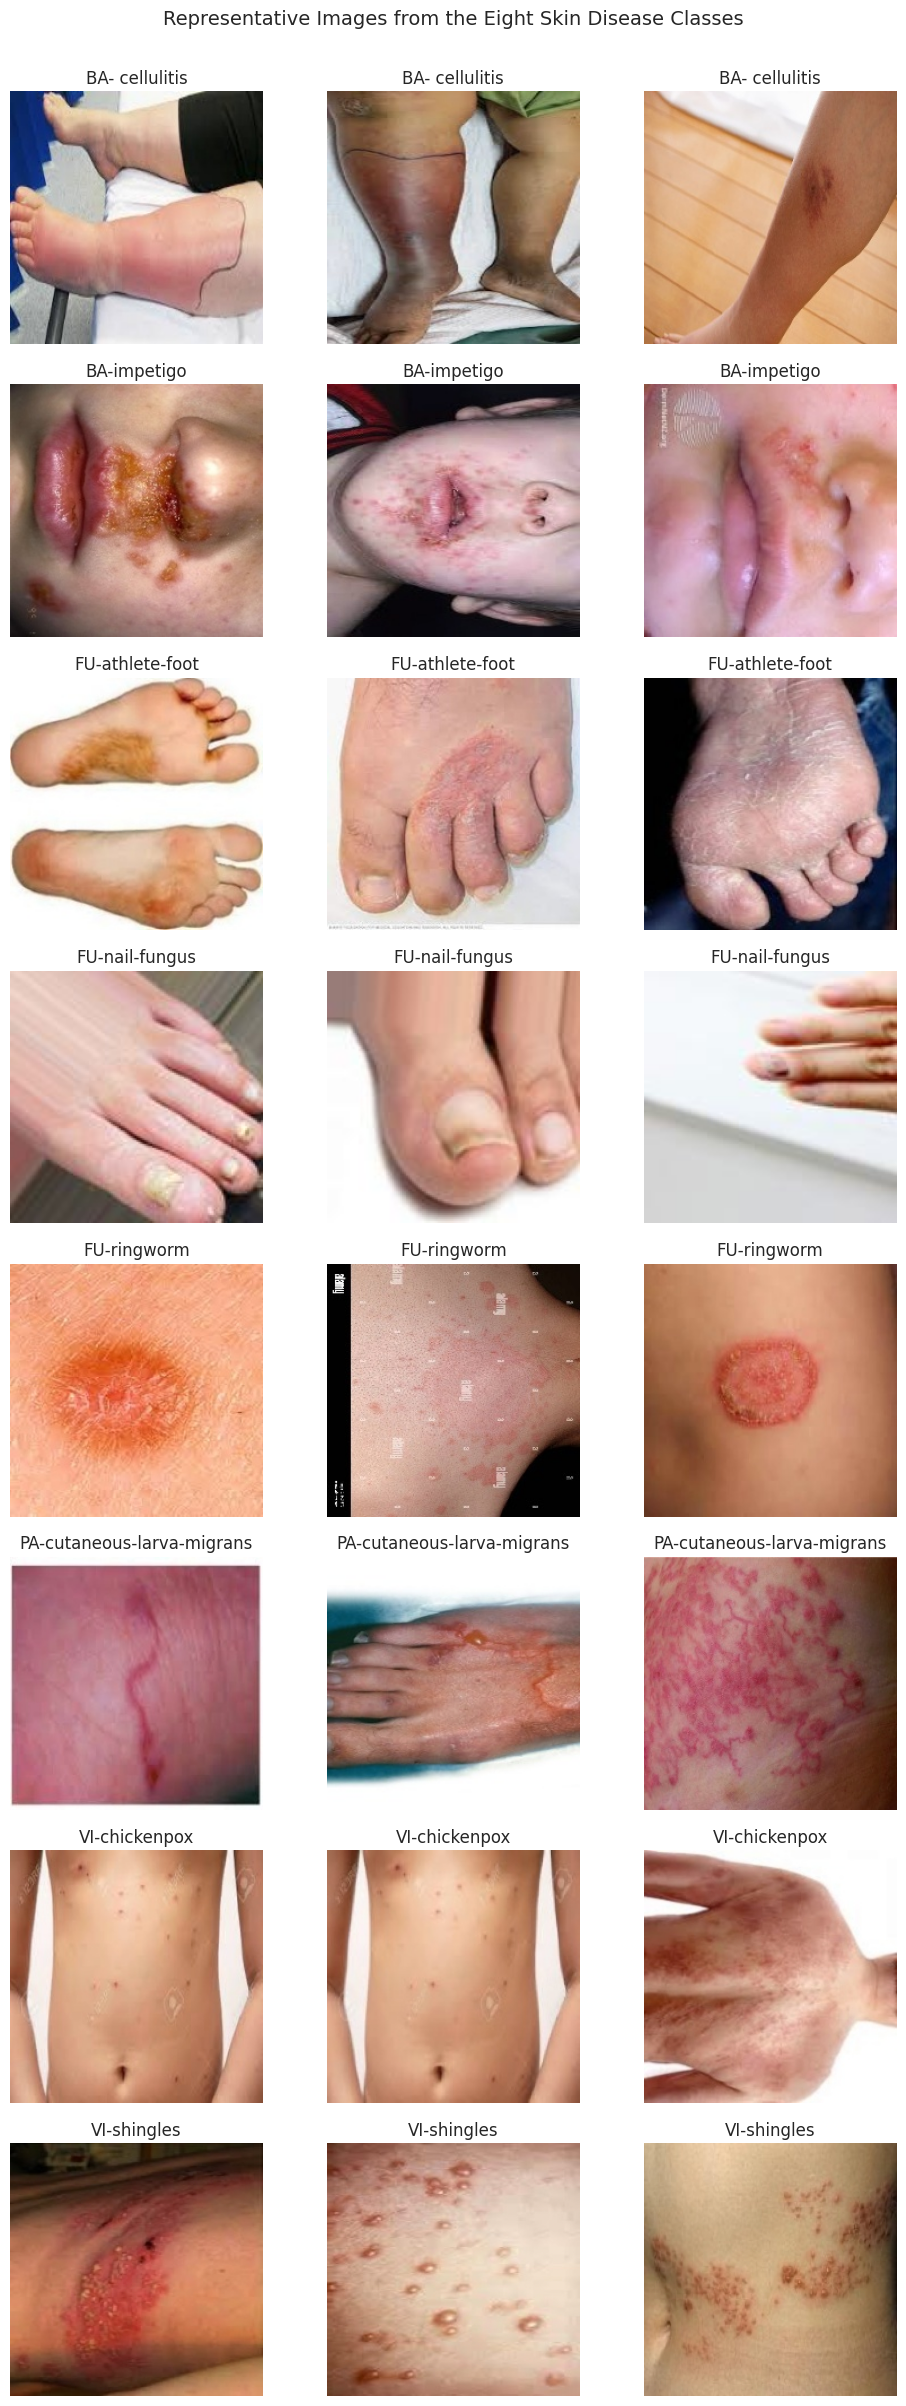

In [ ]:

# EDA 2: Visualize sample images from all disease classes

import matplotlib.pyplot as plt
from PIL import Image
import random

SEED = 42
random.seed(SEED)

disease_classes = sorted(df_working["disease"].unique())

fig, axes = plt.subplots(
    nrows=len(disease_classes),
    ncols=3,
    figsize=(10, 3 * len(disease_classes))
)

for row_idx, disease in enumerate(disease_classes):
    class_images = df_working[
        df_working["disease"] == disease
    ]

    samples = class_images.sample(
        n=min(3, len(class_images)),
        random_state=SEED
    )

    for col_idx, (_, record) in enumerate(samples.iterrows()):
        with Image.open(record["path"]) as img:
            axes[row_idx, col_idx].imshow(img.convert("RGB"))

        axes[row_idx, col_idx].set_title(disease)
        axes[row_idx, col_idx].axis("off")

    # Hide unused subplot positions if a class has fewer than 3 images
    for col_idx in range(len(samples), 3):
        axes[row_idx, col_idx].axis("off")

plt.suptitle(
    "Representative Images from the Eight Skin Disease Classes",
    fontsize=14,
    y=1.002
)
plt.tight_layout()
plt.show()


### **EDA 2: Visual Inspection of Representative Skin Disease Images**

Visual inspection of representative images from the eight skin disease classes highlighted several characteristics relevant to deep learning model development.

**1. Intra-class visual variability:** Images within the same disease class may differ in lesion size, shape, colour, and appearance. Such variability may reflect differences in disease presentation, severity, or stage and could make it more challenging for the model to learn consistent class-specific features.

**2. Variation in image acquisition conditions:** The dataset may contain differences in lighting, magnification, framing, background, and surrounding skin visibility. These variations can introduce irrelevant visual information and affect model generalisation. Image augmentation, including carefully selected brightness and contrast adjustments, may help improve robustness during training.

**3. Differences in image dimensions:** The dataset contains images with varying resolutions, although square images are common. Resizing images to a consistent input size, such as 224 × 224 pixels, will be necessary for the selected convolutional neural network architectures. The resizing method should be chosen carefully to minimise distortion of clinically relevant features.

**4. Potential visual similarity between classes:** Some skin conditions may share visible characteristics, such as redness, vesicles, pustules, or crusting. These similarities may complicate classification based on images alone. The model will therefore need to learn discriminative visual features, and its performance should be assessed separately for each disease class.

Overall, the visual inspection suggests that image variability, acquisition differences, and potential similarities between disease classes should be considered during preprocessing and model development. These observations support the use of consistent image resizing, training-only data augmentation, and comprehensive model evaluation. Visual inspection alone, however, cannot establish diagnostic accuracy or confirm the correctness of the dataset labels.

Also wpold like to point out two thimgs



Above are the exploratory analysis we dim fit to analyse amongst others

We will be proceeding to preparing our data for modeling (Data processsing )

Before resizing or training, we are going to rebuild the training, validation, and test sets from df_working, ensuring that duplicate images cannot leak across splits and that each disease class is represented as evenly as feasible.

# DATA PREPROCESSING

because our earlier duplicate investigation found 11 groups of identical images that appeared across the original training and testing splits. We will use your deduplicated inventory of 1,129 unique images to create new splits, rather than relying on the original split assignments.

We intend to create

- Training set: 70% of the images for model learning.
- Validation set: 15% for monitoring model performance and tuning.
- Test set: 15% for final evaluation on images not used to train or tune the model.

We will also be  using stratified splitting where feasible, so each disease class is represented proportionally in all three sets. our test set must remain untouched until final evaluation.



# Creating new training, validation and test set

In [ ]:

# STEP 1: Split the deduplicated dataset into train, validation, and test sets

from sklearn.model_selection import train_test_split
import pandas as pd

SEED = 42

# Confirm that the working inventory contains unique image records
assert df_working["path"].is_unique, "Duplicate file paths detected."

if "sha256" in df_working.columns:
    assert df_working["sha256"].is_unique, "Duplicate image hashes detected."

# First split: 70% training and 30% temporary data
train_df, temp_df = train_test_split(
    df_working,
    test_size=0.30,
    random_state=SEED,
    stratify=df_working["disease"]
)

# Second split: divide the temporary data equally
# Result: approximately 15% validation and 15% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["disease"]
)

# Assign each image to its new split
train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["new_split"] = "train"
val_df["new_split"] = "validation"
test_df["new_split"] = "test"

# Combine the splits into one inventory
split_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

# Verify that no image hash appears in multiple splits
if "sha256" in split_df.columns:
    split_overlap = split_df.groupby("sha256")["new_split"].nunique()
    assert split_overlap.max() == 1, "Data leakage detected!"

# Display the split sizes
print("TRAINING IMAGES:", len(train_df))
print("VALIDATION IMAGES:", len(val_df))
print("TEST IMAGES:", len(test_df))
print("TOTAL IMAGES:", len(split_df))

print("\nNumber of images per split:")
display(split_df["new_split"].value_counts().to_frame("image_count"))

print("\nDisease distribution across splits:")
distribution = pd.crosstab(
    split_df["disease"],
    split_df["new_split"]
)[["train", "validation", "test"]]

display(distribution)

print("\nPercentage distribution within each disease class:")
percentages = (
    distribution.div(distribution.sum(axis=1), axis=0) * 100
).round(1)

display(percentages)

print("\nVerification passed: no exact duplicate hashes cross splits.")


TRAINING IMAGES: 790
VALIDATION IMAGES: 169
TEST IMAGES: 170
TOTAL IMAGES: 1129

Number of images per split:


,image_count
new_split,
train,790
test,170
validation,169



Disease distribution across splits:


new_split,train,validation,test
disease,,,
BA- cellulitis,117,25,26
BA-impetigo,69,15,15
FU-athlete-foot,107,23,23
FU-nail-fungus,113,24,25
FU-ringworm,78,17,16
PA-cutaneous-larva-migrans,83,18,17
VI-chickenpox,111,23,24
VI-shingles,112,24,24



Percentage distribution within each disease class:


new_split,train,validation,test
disease,,,
BA- cellulitis,69.6,14.9,15.5
BA-impetigo,69.7,15.2,15.2
FU-athlete-foot,69.9,15.0,15.0
FU-nail-fungus,69.8,14.8,15.4
FU-ringworm,70.3,15.3,14.4
PA-cutaneous-larva-migrans,70.3,15.3,14.4
VI-chickenpox,70.3,14.6,15.2
VI-shingles,70.0,15.0,15.0



Verification passed: no exact duplicate hashes cross splits.


The split uses a fixed random seed (42) so that you can reproduce the same results when you rerun the code with the same dataset and environment.

and our data split has completed successfully, and the verification confirms that no exact duplicate image hashes appear across different splits.

# Saving our split inventary

In [ ]:

# Save the new split assignments for reproducibility

split_inventory_path = "/content/skin_disease_split_inventory.csv"

split_df.to_csv(split_inventory_path, index=False)

print("Split inventory saved to:", split_inventory_path)

# Optional: download a copy to your computer
from google.colab import files
files.download(split_inventory_path)


Split inventory saved to: /content/skin_disease_split_inventory.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### **Data Splitting**

The deduplicated dataset of 1,129 unique images was divided into training, validation, and test sets using stratified random sampling. The training set contained 790 images (approximately 70%), the validation set contained 169 images (approximately 15%), and the test set contained 170 images (approximately 15%).

Stratification was used to preserve the relative representation of the eight disease classes across the three subsets. The split verification confirmed that no identical SHA-256 image hashes were distributed across different subsets, reducing the risk of exact-duplicate data leakage. The training set will be used to fit the models, the validation set to monitor performance and guide model selection, and the test set for final evaluation.

# **Processing image for deep learning**

We will now standardize the images to 224 × 224 pixels and prepare them for TensorFlow

In [ ]:

# STEP 2: Define image preprocessing settings and class labels

import tensorflow as tf
import numpy as np

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Create one consistent class-to-index mapping
class_names = sorted(df_working["disease"].unique())

class_to_index = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

index_to_class = {
    index: class_name
    for class_name, index in class_to_index.items()
}

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("\nClass-to-index mapping:")

for class_name, index in class_to_index.items():
    print(f"{index}: {class_name}")

# Confirm that all splits contain only known classes
assert set(train_df["disease"]).issubset(class_names)
assert set(val_df["disease"]).issubset(class_names)
assert set(test_df["disease"]).issubset(class_names)

print("\nPreprocessing settings defined successfully.")


Image size: (224, 224)
Batch size: 32

Class-to-index mapping:
0: BA- cellulitis
1: BA-impetigo
2: FU-athlete-foot
3: FU-nail-fungus
4: FU-ringworm
5: PA-cutaneous-larva-migrans
6: VI-chickenpox
7: VI-shingles

Preprocessing settings defined successfully.


preprocessing settings are defined correctly, and the eight disease classes have been assigned consistent numerical labels from 0 to 7.
We'll now build the TensorFlow image-loading pipeline. This will load images from their file paths, resize them to \(224 \times 224\), convert their pixel values to the range \([0,1]\), and group them into batches of 32.

# Creating our image loading piprline

this line of code will also convert our two web images to PNG because TensorFlow standard image decoder does not consistently support WebP across versions

In [ ]:

# Prepare images for TensorFlow

from pathlib import Path
from PIL import Image
import os
import tensorflow as tf
import matplotlib.pyplot as plt

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# 1. Convert WebP images to PNG for reliable TensorFlow decoding
converted_dir = "/content/converted_webp"
os.makedirs(converted_dir, exist_ok=True)

webp_conversion = {}

for frame in [train_df, val_df, test_df]:
    for image_path in frame["path"].unique():
        if Path(image_path).suffix.lower() == ".webp":
            if image_path not in webp_conversion:
                output_path = os.path.join(
                    converted_dir,
                    Path(image_path).stem + "_converted.png"
                )

                with Image.open(image_path) as img:
                    img.convert("RGB").save(output_path, format="PNG")

                webp_conversion[image_path] = output_path

# Update paths in each split; original images remain untouched
for frame in [train_df, val_df, test_df]:
    frame["path"] = frame["path"].replace(webp_conversion)

print("WebP images converted:", len(webp_conversion))

# 2. Define the image-loading and preprocessing function
def load_and_preprocess_image(image_path, label):
    image_bytes = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image, label

# 3. Create TensorFlow datasets
def create_dataset(dataframe, training=False):
    paths = dataframe["path"].astype(str).to_numpy()
    labels = dataframe["disease"].map(class_to_index).to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("\nTensorFlow datasets created successfully.")


WebP images converted: 2

TensorFlow datasets created successfully.


Lets vey the processing

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel minimum: 0.0
Pixel maximum: 1.0
Image data type: <dtype: 'float32'>


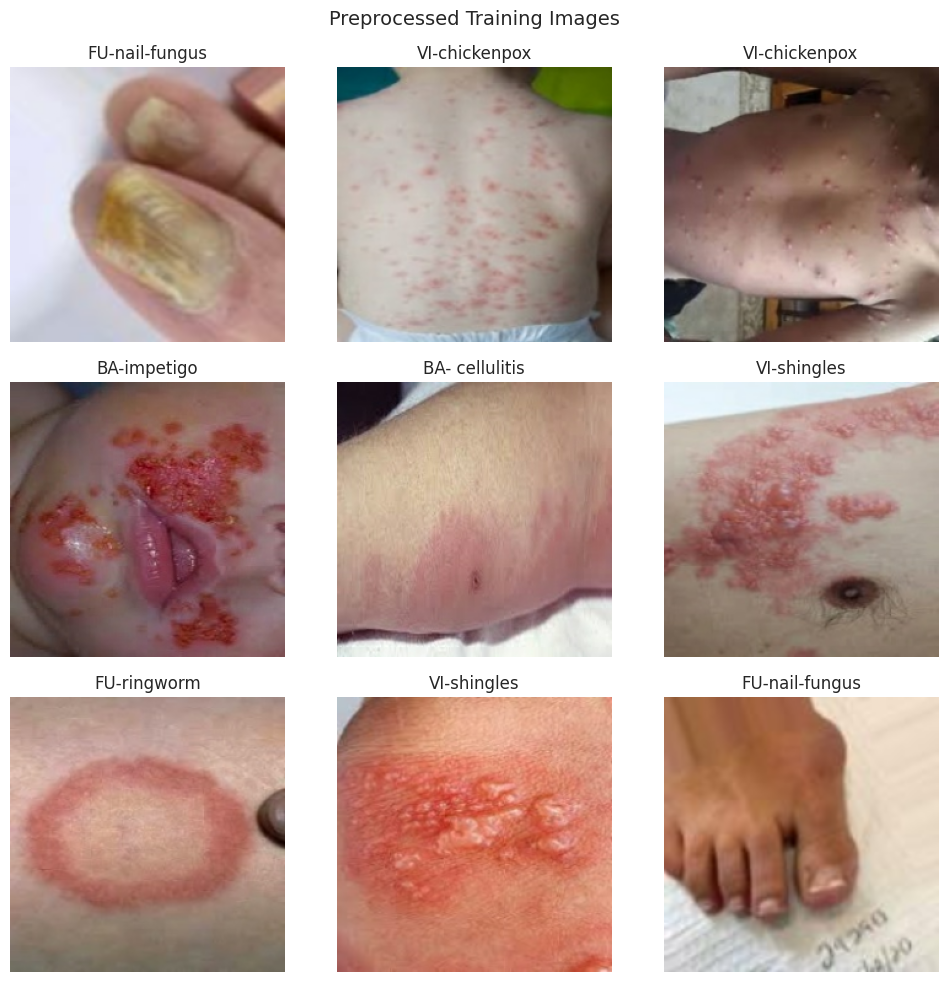

In [ ]:

# STEP 4: Inspect a batch of preprocessed training images

images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel minimum:", float(tf.reduce_min(images)))
print("Pixel maximum:", float(tf.reduce_max(images)))
print("Image data type:", images.dtype)

# Display nine sample images
plt.figure(figsize=(10, 10))

for i in range(min(9, images.shape[0])):
    plt.subplot(3, 3, i + 1)

    plt.imshow(images[i].numpy())
    plt.title(index_to_class[int(labels[i].numpy())])
    plt.axis("off")

plt.suptitle("Preprocessed Training Images", fontsize=14)
plt.tight_layout()
plt.show()


Our pipeline shuffles only the training data. Validation and test data remain unshuffled, and neither receives random augmentation at this stage.

results indicate that image loading, resizing, label encoding, and pixel normalization are functioning as intended. The output alone does not establish that the disease labels are correct or that the model will classify diseases accurately.

### **Image Preprocessing and Dataset Preparation**

The images were resized to 224 × 224 pixels to ensure a consistent input dimension across the dataset. Each image was represented using three colour channels (RGB), and pixel intensities were normalized to the range of 0–1 by dividing the pixel values by 255. Disease categories were converted into integer labels to facilitate model training.

The dataset was organized into training, validation, and testing subsets using a stratified split of approximately 70%, 15%, and 15%, respectively. Exact duplicate images were removed before splitting to reduce the risk of data leakage between subsets. The resulting TensorFlow datasets were batched in groups of 32 images and configured for efficient data loading.

The successful preprocessing checks confirmed the expected image and label batch dimensions, floating-point data type, and normalized pixel range. These preparations provide a consistent input format for training and evaluating the image-classification models.

# MODELLING

# Model 1  a custom Convolutional Neural Network (CNN)

We will start with a custom CNN as our baseline model. Later, we will compare its performance with a transfer-learning model such as MobileNetV2.

Our reason for choosing the CNN

- Convolutional layers: learn visual features such as edges, textures, and lesion patterns.
- Max pooling: reduces spatial dimensions and computational requirements.
- Global average pooling: summarizes learned feature maps with fewer parameters than flattening the entire feature map.
- Dropout: helps reduce overfitting during training.
- Softmax output: produces a probability distribution across the eight disease classes.
- Sparse categorical cross-entropy: suits integer-encoded class labels.

### **CNN Architecture and Model Configuration**

A custom Convolutional Neural Network (CNN) was developed as the baseline image-classification model. The network accepts RGB images resized to 224 × 224 × 3 pixels. It comprises three convolutional blocks containing 32, 64, and 128 filters, respectively. Each convolutional layer uses a 3 × 3 kernel, the ReLU activation function, and same padding, followed by a 2 × 2 max-pooling layer to reduce spatial dimensions.

The extracted feature maps are passed through a global average pooling layer and a fully connected layer containing 128 neurons with ReLU activation. A dropout rate of 0.4 is applied to reduce overfitting. The final dense layer contains eight neurons corresponding to the eight disease classes, with softmax activation to generate class probabilities.

The model is compiled using the Adam optimizer with a learning rate of 0.001 and sparse categorical cross-entropy as the loss function. Accuracy is used as the training and validation metric. The model is trained for a maximum of 20 epochs with a batch size of 32. Early stopping monitors validation loss with a patience of five epochs and restores the weights associated with the best validation loss.

This architecture was selected as a baseline to assess the ability of a CNN trained from scratch to learn discriminative visual features from the skin-disease image dataset. Its performance is subsequently compared with a transfer-learning approach.

In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, models

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Build the baseline CNN
cnn_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Convolutional block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolutional block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolutional block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(len(class_names), activation="softmax")
])

# Configure the model
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the architecture
cnn_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,792 (432.78 KB)

 Trainable params: 110,792 (432.78 KB)

 Non-trainable params: 0 (0.00 B)

# Training our baseline CNN

In [ ]:

# Stop training when validation loss stops improving
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history_cnn = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 22s 454ms/step - accuracy: 0.1405 - loss: 2.0695 - val_accuracy: 0.1953 - val_loss: 2.0583
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - accuracy: 0.1785 - loss: 2.0459 - val_accuracy: 0.2308 - val_loss: 2.0207
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - accuracy: 0.2114 - loss: 1.9933 - val_accuracy: 0.2249 - val_loss: 2.0001
Epoch 4/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - accuracy: 0.2582 - loss: 1.9259 - val_accuracy: 0.2781 - val_loss: 1.8777
Epoch 5/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 63ms/step - accuracy: 0.2266 - loss: 1.9012 - val_accuracy: 0.2663 - val_loss: 1.8623
Epoch 6/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - accuracy: 0.2608 - loss: 1.8539 - val_accuracy: 0.2899 - val_loss: 1.8220
Epoch 7/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 66ms/step - accuracy: 0.2620 - loss: 1.8664 - val_accuracy: 0.2544 - val_loss: 1.8266
Epoch 8/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - accuracy: 0.2557 - loss: 1.8461 - val_accuracy: 0.2722 -

our result suggest that

The model is learning: training accuracy increased from 14.05% in epoch 1 to 35.32% in epoch 20.



Validation performance improved: validation accuracy rose from 19.53% to 33.73%.



There is no obvious large training–validation accuracy gap: the final difference is about 1.59 percentage points. However, this alone does not rule out underfitting or other generalization problems.



The model may be underfitting: both training and validation accuracy remain relatively low, suggesting that the custom CNN has not yet learned sufficiently discriminative features.


# Traininng performance visualization

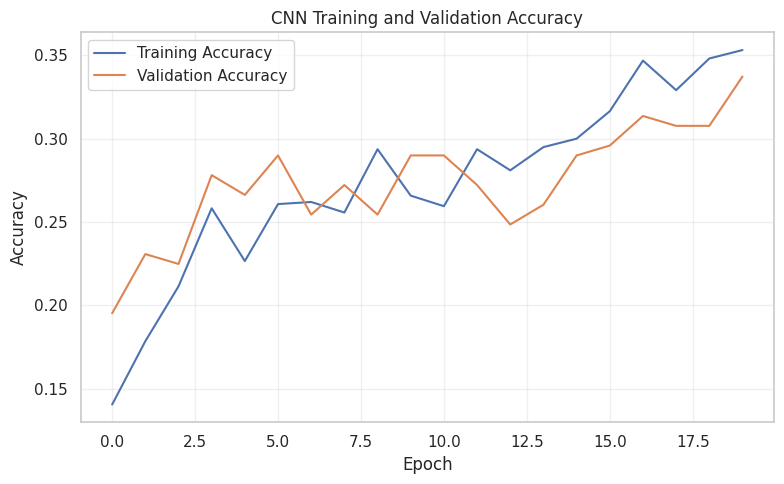

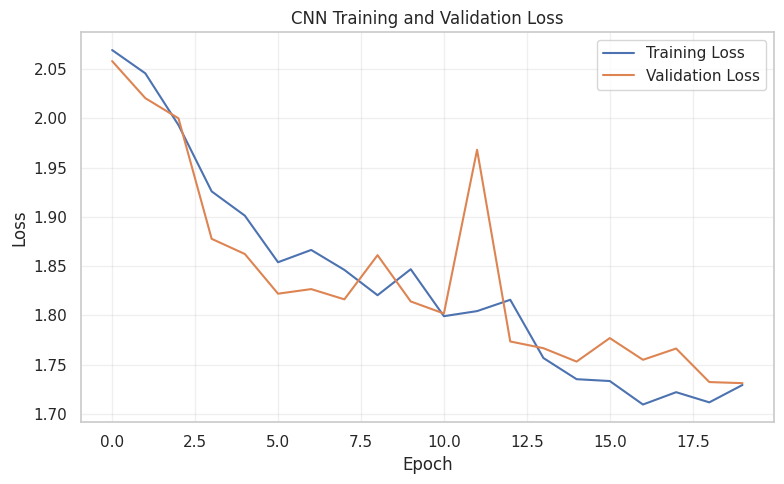

In [ ]:

import matplotlib.pyplot as plt

# Extract recorded metrics
train_accuracy = history_cnn.history["accuracy"]
val_accuracy = history_cnn.history["val_accuracy"]
train_loss = history_cnn.history["loss"]
val_loss = history_cnn.history["val_loss"]

# Plot accuracy
plt.figure(figsize=(8, 5))
plt.plot(train_accuracy, label="Training Accuracy")
plt.plot(val_accuracy, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot loss
plt.figure(figsize=(8, 5))
plt.plot(train_loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### **CNN Training and Validation Performance**

The baseline CNN demonstrated gradual improvement in training and validation accuracy over the training period. Training accuracy increased from 14.05% in the first epoch to 35.32% in the final epoch, while validation accuracy increased from 19.53% to 33.73%. The final training and validation losses were 1.7292 and 1.7310, respectively.

Although the model learned useful image features, its classification accuracy remained limited. The relatively close final training and validation accuracy values suggest that a substantial generalization gap was not evident at the end of training. Nevertheless, the results indicate that further modelling approaches should be investigated to improve classification performance.

In [ ]:
# SAVING OUR MODEL SUMMARY

cnn_model.summary()



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 332,378 (1.27 MB)

 Trainable params: 110,792 (432.78 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 221,586 (865.57 KB)

# Model 2 MobileNetV2 model

Our first CNN achieved 35.32% training accuracy and 33.73% validation accuracy. MobileNetV2 uses features learned from a much larger ImageNet dataset, which may help it learn useful visual patterns with fewer training examples. We will test whether this improves performance .

In [ ]:

# ASSISTED BY CHATCGPT AI AND GEMINI
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# Set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

# Load MobileNetV2 pretrained on ImageNet
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained layers initially
base_model.trainable = False

# Build the transfer-learning model
inputs = layers.Input(shape=(224, 224, 3))

# Convert pixels from [0, 1] to [-1, 1]
x = layers.Rescaling(scale=2.0, offset=-1.0)(inputs)

# Extract pretrained image features
x = base_model(x, training=False)

# Add a classifier for our eight disease classes
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

mobilenet_model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="MobileNetV2_Skin_Disease_Classifier"
)

# Configure the model
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture and parameters
mobilenet_model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV2_Skin_Disease_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │        10,248 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,268,232 (8.65 MB)

 Trainable params: 10,248 (40.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

This model contains

Base model: pretrained MobileNetV2 convolutional feature extractor.



Frozen layers: pretrained weights remain unchanged during the initial training stage.



Global average pooling: summarizes the extracted feature maps.



Dropout: rate of 0.3 to help reduce overfitting.



Output layer: eight neurons with softmax activation.



Loss function: sparse categorical cross-entropy.



Optimizer: Adam, learning rate 0.001.



Input scaling: transforms normalized pixels from 0–1 to −1–1, the expected MobileNetV2 input range.

### **Model 2: MobileNetV2 Transfer Learning**

MobileNetV2 was selected as the second image-classification approach to investigate whether transfer learning could improve upon the custom CNN baseline. The model uses pretrained ImageNet weights and excludes the original classification layer. The pretrained convolutional base generates feature maps with an output shape of 7 × 7 × 1,280 from the 224 × 224 RGB input images.

A global average pooling layer converts these feature maps into a 1,280-element feature vector. A dropout layer with a rate of 0.3 is then applied, followed by a dense output layer containing eight neurons with softmax activation to classify the eight disease categories.

The input images are rescaled from the range 0–1 to −1–1 to match MobileNetV2's expected input range. During the initial training stage, the pretrained base is frozen, leaving 10,248 trainable parameters and 2,257,984 non-trainable parameters, out of 2,268,232 total parameters.

The model is compiled with the Adam optimizer, a learning rate of 0.001, and sparse categorical cross-entropy loss. Accuracy is used as the training metric. This feature-extraction approach allows the newly added classification layer to learn from the study dataset while retaining the pretrained feature representations.

# Training MobileNetV2

In [ ]:

# Early stopping for transfer learning
early_stopping_mobilenet = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Train the model
history_mobilenet = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stopping_mobilenet],
    verbose=1
)


Epoch 1/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 26s 570ms/step - accuracy: 0.3544 - loss: 1.8660 - val_accuracy: 0.7337 - val_loss: 0.9294
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - accuracy: 0.7570 - loss: 0.8071 - val_accuracy: 0.8876 - val_loss: 0.5176
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.8646 - loss: 0.4928 - val_accuracy: 0.9053 - val_loss: 0.3984
Epoch 4/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - accuracy: 0.8899 - loss: 0.3718 - val_accuracy: 0.9467 - val_loss: 0.3320
Epoch 5/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 73ms/step - accuracy: 0.9165 - loss: 0.3042 - val_accuracy: 0.9349 - val_loss: 0.2873
Epoch 6/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.9443 - loss: 0.2451 - val_accuracy: 0.9290 - val_loss: 0.2653
Epoch 7/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9608 - loss: 0.1998 - val_accuracy: 0.9467 - val_loss: 0.2377
Epoch 8/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.9633 - loss: 0.1698 - val_accuracy: 0.9467 -

What we can deduce from output on the MobileNetV2 model are

- Strong learning performance: training accuracy increased from 35.44% in epoch 1 to 99.75% in epoch 20.
- Strong validation performance: validation accuracy increased from 73.37% to 94.08%.
- Some overfitting is possible: the final training accuracy exceeds validation accuracy by approximately 5.67 percentage points. The validation loss continues to decrease overall, however, so this gap alone does not establish severe overfitting.
- Best validation loss: the lowest reported validation loss was 0.1467 at epoch 20, so early stopping restored the weights from that epoch.

These results suggest that transfer learning is more effective than the custom CNN on this dataset's validation split.

MobileNetV2's validation accuracy is 60.35 percentage points higher than the custom CNN's reported final validation accuracy.

### **Performance of the MobileNetV2 Transfer-Learning Model**

The MobileNetV2 model demonstrated substantial improvement during training. Training accuracy increased from 35.44% in the first epoch to 99.75% in the twentieth epoch, while validation accuracy increased from 73.37% to 94.08%. The final training and validation losses were 0.0500 and 0.1467, respectively.

Compared with the custom CNN baseline, which achieved a final validation accuracy of 33.73%, MobileNetV2 achieved a final validation accuracy of 94.08%. This represents an improvement of 60.35 percentage points in the reported final-epoch validation accuracy. The results suggest that the pretrained feature representations used by MobileNetV2 were more effective for this dataset than the features learned by the custom CNN from scratch.

The higher training accuracy relative to validation accuracy indicates a potential generalization gap, which should be considered when interpreting the model's performance. Final conclusions will be based on evaluation using the held-out test set, together with class-specific precision, recall, F1-scores, and a confusion matrix.

# ploting our training and validationcurve

These plots will help us visualize the learning behaviour and check for signs of overfitting.

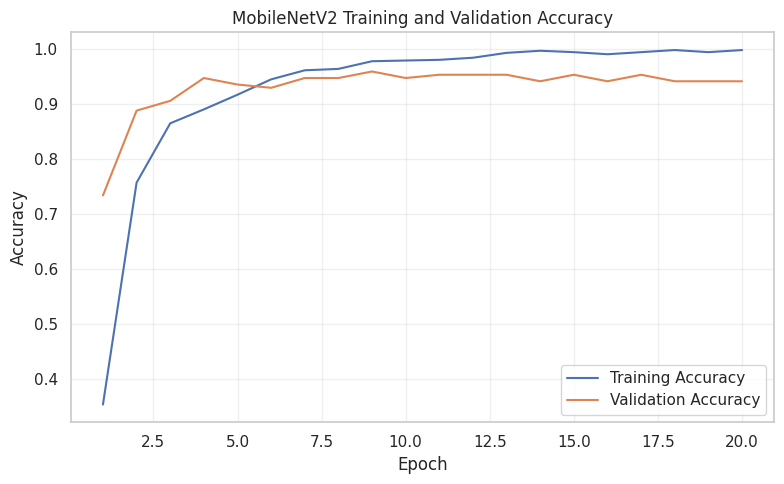

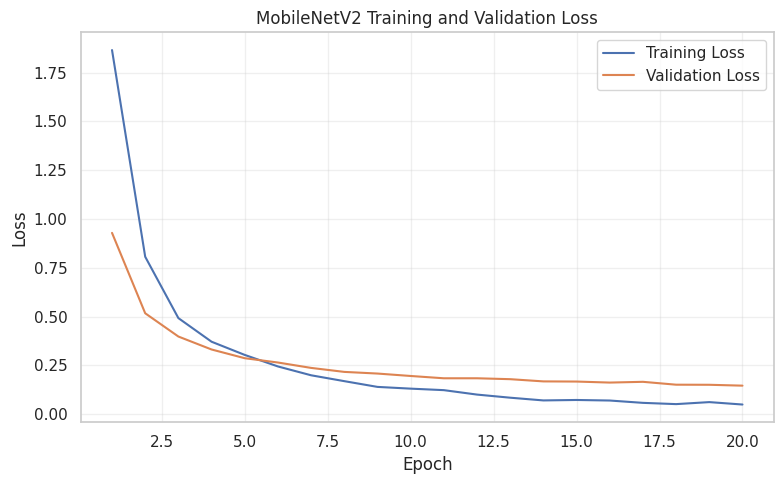

In [ ]:

# ASSISTED BY CHATCGPT AI AND GEMINI
import matplotlib.pyplot as plt

# Extract MobileNetV2 training history
train_acc = history_mobilenet.history["accuracy"]
val_acc = history_mobilenet.history["val_accuracy"]
train_loss = history_mobilenet.history["loss"]
val_loss = history_mobilenet.history["val_loss"]

# Accuracy curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(train_acc) + 1), train_acc, label="Training Accuracy")
plt.plot(range(1, len(val_acc) + 1), val_acc, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV2 Training and Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(train_loss) + 1), train_loss, label="Training Loss")
plt.plot(range(1, len(val_loss) + 1), val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MobileNetV2 Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Interpretation/Observation of MobileNetV2 Learning Curves

The training and validation accuracy curves indicate that MobileNetV2 learned useful features rapidly during the initial training epochs. Validation accuracy increased substantially during the early stages and remained approximately between 94% and 96% during much of the later training period. The final training and validation accuracies were 99.75% and 94.08%, respectively.

The training and validation loss curves both showed an overall downward trend. Training loss decreased to 0.0500, while validation loss decreased to 0.1467 by the final epoch. Although the difference between training and validation accuracy suggests some degree of overfitting, the continued reduction in validation loss indicates that validation performance did not deteriorate substantially during training.

Overall, the learning curves support the use of MobileNetV2 as a promising transfer-learning model for this classification task. Nevertheless, its final performance must be assessed using the held-out test dataset and class-specific evaluation metrics before drawing conclusions about its generalization ability.

# Evaluation of both models on the test set

We have 170 test images that have not been used for training or validation. We will use them to compare the custom CNN and MobileNetV2 fairly.

6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 400ms/step
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 919ms/step
TEST ACCURACY COMPARISON


,Model,Test Accuracy
0,Custom CNN,0.388235
1,MobileNetV2,0.964706



CUSTOM CNN: CLASSIFICATION REPORT
                            precision    recall  f1-score   support

            BA- cellulitis     0.3500    0.2692    0.3043        26
               BA-impetigo     0.0000    0.0000    0.0000        15
           FU-athlete-foot     0.3846    0.2174    0.2778        23
            FU-nail-fungus     0.3542    0.6800    0.4658        25
               FU-ringworm     0.8571    0.3750    0.5217        16
PA-cutaneous-larva-migrans     0.3333    0.1765    0.2308        17
             VI-chickenpox     0.4167    0.4167    0.4167        24
               VI-shingles     0.3673    0.7500    0.4932        24

                  accuracy                         0.3882       170
                 macro avg     0.3829    0.3606    0.3388       170
              weighted avg     0.3823    0.3882    0.3532       170


MOBILENETV2: CLASSIFICATION REPORT
                            precision    recall  f1-score   support

            BA- cellulitis     0.9600    

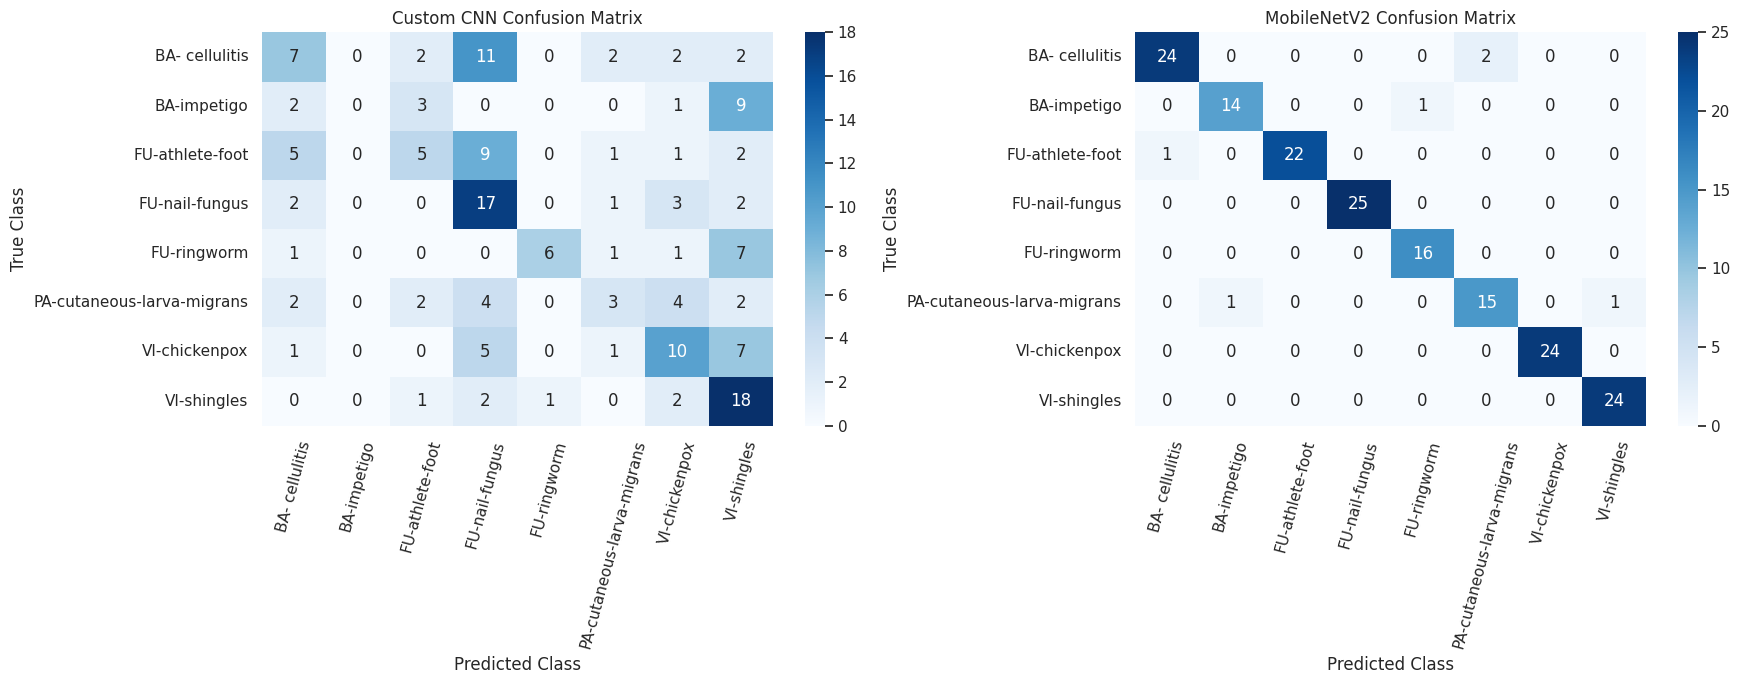

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Get the true test labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Generate predictions from both models
cnn_probabilities = cnn_model.predict(test_ds, verbose=1)
mobilenet_probabilities = mobilenet_model.predict(test_ds, verbose=1)

y_pred_cnn = np.argmax(cnn_probabilities, axis=1)
y_pred_mobilenet = np.argmax(mobilenet_probabilities, axis=1)

# Compare overall test accuracy
cnn_test_accuracy = accuracy_score(y_true, y_pred_cnn)
mobilenet_test_accuracy = accuracy_score(y_true, y_pred_mobilenet)

comparison_df = pd.DataFrame({
    "Model": ["Custom CNN", "MobileNetV2"],
    "Test Accuracy": [
        cnn_test_accuracy,
        mobilenet_test_accuracy
    ]
})

print("TEST ACCURACY COMPARISON")
display(comparison_df)

# Detailed classification reports
print("\nCUSTOM CNN: CLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred_cnn,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("\nMOBILENETV2: CLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred_mobilenet,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

# Plot confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, predictions, title in [
    (axes[0], y_pred_cnn, "Custom CNN Confusion Matrix"),
    (axes[1], y_pred_mobilenet, "MobileNetV2 Confusion Matrix")
]:
    cm = confusion_matrix(
        y_true,
        predictions,
        labels=list(range(len(class_names)))
    )
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("True Class")
    ax.tick_params(axis="x", rotation=75)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()


These test results give us a clear comparison between our two models. MobileNetV2 is the stronger model on the held-out test set, achieving 96.47% accuracy compared with 38.82% for our custom CNN.

MobileNetV2 improved test accuracy by 57.65 percentage points. Its macro F1-score of 96.05% also indicates strong performance across the eight classes, rather than accuracy being driven only by the larger classes.



### **Comparative Evaluation of the Classification Models**

The custom CNN and MobileNetV2 were evaluated using the same held-out test dataset containing 170 images across eight skin disease categories. The custom CNN achieved a test accuracy of 38.82%, a macro-averaged precision of 38.29%, a macro-averaged recall of 36.06%, and a macro F1-score of 33.88%.

In comparison, MobileNetV2 achieved a test accuracy of 96.47%, macro precision of 95.96%, macro recall of 96.19%, and macro F1-score of 96.05%. Its weighted F1-score was 96.46%. These results represent an improvement of 57.65 percentage points in test accuracy over the custom CNN.

MobileNetV2 achieved an F1-score of 100% for nail fungus and chickenpox. Cutaneous larva migrans had the lowest class-specific F1-score at 88.24%, followed by impetigo at 93.33% and cellulitis at 94.12%. The custom CNN showed substantially weaker performance, including zero precision and recall for impetigo.

Based on these test-set results, MobileNetV2 was selected as the stronger model for this image-classification task. However, the findings are limited to the available dataset and test split. Additional evaluation on independently collected images, with attention to patient-level separation and possible dataset-specific biases, is necessary before considering real-world clinical applications. The model should be regarded as a research prototype rather than a validated diagnostic tool.

Confusion matrix

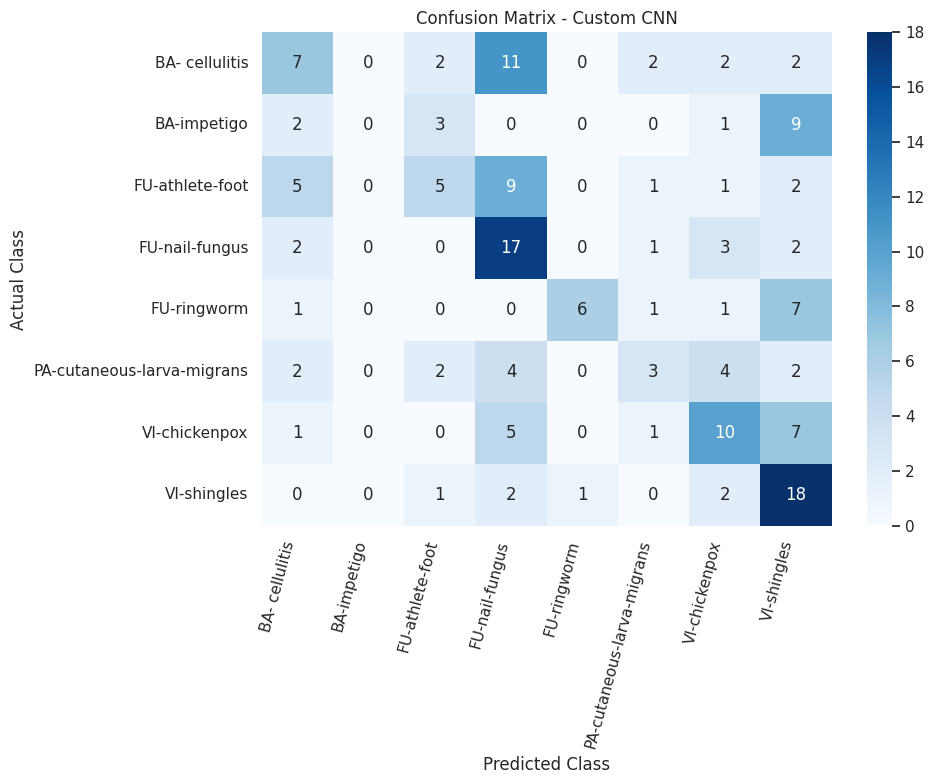

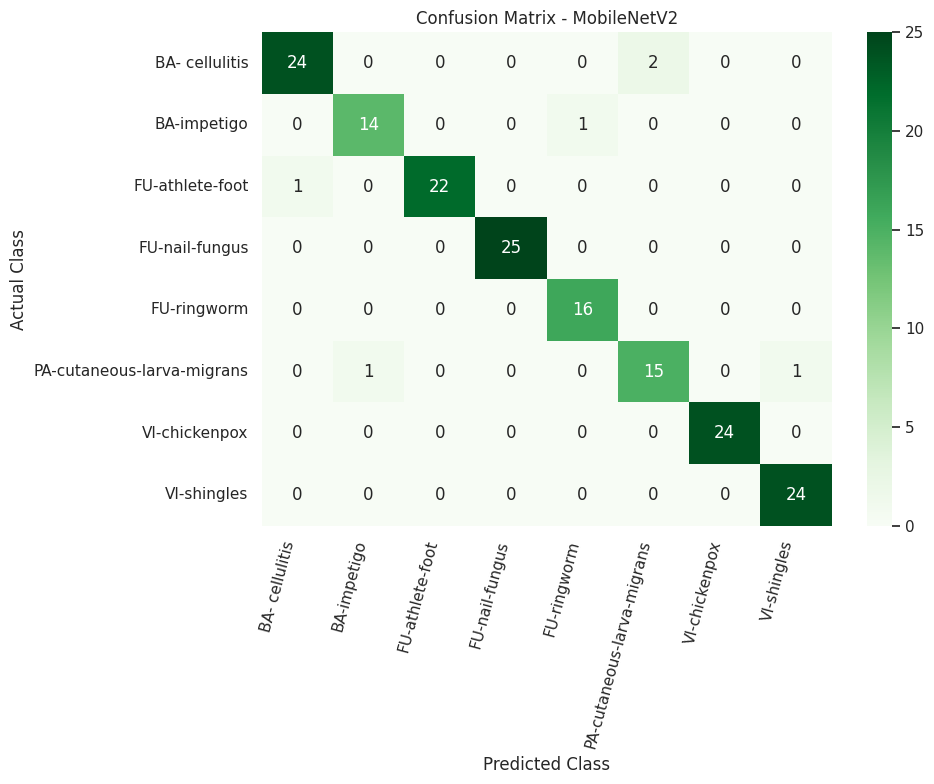

In [ ]:
# ASSISTED BY CHATGPT AI AND GEMINI
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Confusion matrix for the custom CNN
cm_cnn = confusion_matrix(
    y_true,
    y_pred_cnn,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_cnn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Confusion Matrix - Custom CNN")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=75, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Confusion matrix for MobileNetV2
cm_mobilenet = confusion_matrix(
    y_true,
    y_pred_mobilenet,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_mobilenet,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Confusion Matrix - MobileNetV2")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=75, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


### **Confusion Matrix Analysis**

The confusion matrices were examined to identify the classification patterns of the custom CNN and MobileNetV2 models across the eight skin disease categories. The custom CNN demonstrated considerable confusion between classes. It correctly classified 7 of 26 cellulitis images, none of the 15 impetigo images, 5 of 23 athlete's foot images, 17 of 25 nail fungus images, 6 of 16 ringworm images, 3 of 17 cutaneous larva migrans images, 10 of 24 chickenpox images, and 18 of 24 shingles images. Frequent errors included predicting cellulitis and athlete's foot as nail fungus, impetigo and ringworm as shingles, and cutaneous larva migrans as nail fungus or chickenpox.

In contrast, MobileNetV2 correctly classified 164 of the 170 test images. It achieved perfect classification on the test samples for nail fungus, ringworm, chickenpox, and shingles. The remaining errors comprised two cellulitis images classified as cutaneous larva migrans, one impetigo image classified as ringworm, one athlete's foot image classified as cellulitis, and two cutaneous larva migrans images classified as impetigo and shingles.

The confusion matrix analysis is consistent with the overall test accuracy results and demonstrates substantially better classification performance by MobileNetV2 than by the custom CNN. Nevertheless, the relatively small test sample sizes for individual classes and the use of a single dataset split limit the strength of generalization claims. Independent external validation is required before the model could be considered for clinical use.

OUR FINAL CHECK

MobileNetV2 confusion matrix sums to 170 test images and agrees with the reported 164 correct predictions.
However, the custom CNN confusion matrix appears to sum to 65 correct predictions, whereas its classification report implies 66 correct predictions from the 38.82% accuracy. This small discrepancywill be investigated before the final report is submitted.


In [ ]:
# ASSISTED BY CLAUD AI AND GEMINI
print("Number of test labels:", len(y_true))

print("Custom CNN correct predictions:",
      int((y_true == y_pred_cnn).sum()))

print("Custom CNN accuracy:",
      round(float((y_true == y_pred_cnn).mean()), 6))

print("MobileNetV2 correct predictions:",
      int((y_true == y_pred_mobilenet).sum()))

print("MobileNetV2 accuracy:",
      round(float((y_true == y_pred_mobilenet).mean()), 6))


Number of test labels: 170
Custom CNN correct predictions: 66
Custom CNN accuracy: 0.388235
MobileNetV2 correct predictions: 164
MobileNetV2 accuracy: 0.964706


Final observation

MobileNetV2 correctly classified 164 of the 170 test images, compared with 66 for the custom CNN. This is an improvement of 57.65 percentage points in test accuracy, supporting MobileNetV2 as the preferred model for this experiment.

# SAVING OUR MODEL
so that we can load it without stress later or anytime

In [6]:

# Save the selected model in Keras format
model_path = "/content/mobilenetv2_skin_disease_classifier.keras"

mobilenet_model.save(model_path)

print("Model saved successfully:", model_path)


NameError: name 'mobilenet_model' is not defined

Downloading our model

In [ ]:

from google.colab import files

files.download("/content/mobilenetv2_skin_disease_classifier.keras")


FileNotFoundError: Cannot find file: /content/mobilenetv2_skin_disease_classifier.keras

# MODEL DEPLOYING(MobileNetV2)

Installing Gradio

In [ ]:

%pip install -q gradio


Loading our data

In [2]:

import tensorflow as tf
import numpy as np
import gradio as gr
from PIL import Image

MODEL_PATH = "/content/mobilenetv2_skin_disease_classifier.keras"

# Load the trained model
mobilenet_model = tf.keras.models.load_model(MODEL_PATH)

# Define the eight class labels in the original order
class_names = [
    "BA- cellulitis",
    "BA-impetigo",
    "FU-athlete-foot",
    "FU-nail-fungus",
    "FU-ringworm",
    "PA-cutaneous-larva-migrans",
    "VI-chickenpox",
    "VI-shingles"
]

print("Model loaded successfully.")
print("Number of output classes:", mobilenet_model.output_shape[-1])
print("Class labels:", class_names)


ValueError: File not found: filepath=/content/mobilenetv2_skin_disease_classifier.keras. Please ensure the file is an accessible `.keras` zip file.

We encountered an error with the above line of code after changing our runtime to CPU we reached out limit for GPU runtime

 the error suggested that Google Colab cannot find the saved MobileNetV2 model at that location. our model may still be safe; the file may simply not be present in the current Colab session. This can happen when the runtime restarts or the model was saved but not downloaded.

Fixing it by first checking if our Model still exist, and i am very sure i saved and downloade it

In [5]:

import os

MODEL_PATH = "/content/mobilenetv2_skin_disease_classifier.keras"

print("Model file exists:", os.path.exists(MODEL_PATH))
print("Files in /content:")
print(os.listdir("/content")[:30])


Model file exists: True
Files in /content:
['.config', 'mobilenetv2_skin_disease_classifier.keras', 'sample_data']


Lets upload our model again

In [4]:

from google.colab import files

uploaded = files.upload()


Saving mobilenetv2_skin_disease_classifier.keras to mobilenetv2_skin_disease_classifier.keras


**Creating our image prediction function**

This function will resize an uploaded image, normalize it exactly as we did during our training, and return the three highest predicted classes.

In [ ]:
# ASSISTED BY CHATGPT
def predict_skin_disease(image):
    if image is None:
        return {}

    # Convert image to RGB and resize
    image = image.convert("RGB").resize((224, 224))

    # Normalize pixels to [0, 1]
    image_array = np.asarray(image, dtype=np.float32) / 255.0

    # Add batch dimension
    image_array = np.expand_dims(image_array, axis=0)

    # Predict class probabilities
    probabilities = mobilenet_model.predict(
        image_array, verbose=0
    )[0]

    # Return the top three predictions
    top_indices = np.argsort(probabilities)[::-1][:3]

    return {
        class_names[i]: float(probabilities[i])
        for i in top_indices
    }


# Building and launching our web interface

In [ ]:
# ASSISTED BY CLAUD AI AND GEMINI
demo = gr.Interface(
    fn=predict_skin_disease,
    inputs=gr.Image(
        type="pil",
        label="Upload a skin image"
    ),
    outputs=gr.Label(
        num_top_classes=3,
        label="Top predicted classes"
    ),
    title="Skin Disease Image Classification",
    description=(
        "Research prototype using MobileNetV2 to classify images "
        "into eight skin-disease categories. "
        "For educational and research purposes only. "
        "This tool is not a medical diagnostic device."
    )
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c99cfa722713025cb2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


**OUR FIRST LAUNCHING ABOVE INITIALLY FLAGGED ERROR WHICH WE ADDRESSED BELOW AND HAS BEEN WHEN WE RERAN IT**

Python does not recognize gr, which is the alias for the Gradio library. This usually happens when the import cell was not run or the Colab runtime was restarted.

retrying in our next line of code

# DEBUGGING

In [ ]:
# ASSISTED BY CHTGPT AI AND GEMINI
%pip install -q gradio

import gradio as gr
import numpy as np
import tensorflow as tf
from PIL import Image

print("Gradio version:", gr.__version__)
print("Gradio imported successfully!")


Gradio version: 6.29.0
Gradio imported successfully!


# Checking if prediction function still exist

In [13]:

print("Prediction function available:", "predict_skin_disease" in globals())
print("Model available:", "mobilenet_model" in globals())
print("Class labels available:", "class_names" in globals())


Prediction function available: True
Model available: True
Class labels available: True


# LAUNCHING INTERFACE AGAIN

Moment of truth

In [12]:
import tensorflow as tf
import numpy as np
import gradio as gr
from PIL import Image
import os

# 1. Load the model from the local path
MODEL_PATH = "/content/mobilenetv2_skin_disease_classifier.keras"

# Fallback check to ensure the file exists before loading
if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        f"Could not find model at {MODEL_PATH}. "
        "Please ensure your model file is uploaded to the /content directory."
    )

mobilenet_model = tf.keras.models.load_model(MODEL_PATH)

# 2. Define the class names in the correct order
class_names = [
    "BA- cellulitis",
    "BA-impetigo",
    "FU-athlete-foot",
    "FU-nail-fungus",
    "FU-ringworm",
    "PA-cutaneous-larva-migrans",
    "VI-chickenpox",
    "VI-shingles"
]

# 3. Define the prediction function
def predict_skin_disease(image):
    if image is None:
        return {}

    # Convert image to RGB and resize
    image = image.convert("RGB").resize((224, 224))

    # Normalize pixels to [0, 1]
    image_array = np.asarray(image, dtype=np.float32) / 255.0

    # Add batch dimension
    image_array = np.expand_dims(image_array, axis=0)

    # Predict class probabilities
    probabilities = mobilenet_model.predict(image_array, verbose=0)[0]

    # Return the top three predictions
    top_indices = np.argsort(probabilities)[::-1][:3]

    return {
        class_names[i]: float(probabilities[i])
        for i in top_indices
    }

# 4. Build and launch the Gradio interface
demo = gr.Interface(
    fn=predict_skin_disease,
    inputs=gr.Image(type="pil", label="Upload a skin image"),
    outputs=gr.Label(
        num_top_classes=3,
        label="Top predicted classes"
    ),
    title="Skin Disease Image Classification",
    description=(
        "Research prototype for classifying images into eight "
        "skin-disease categories. For educational and research "
        "purposes only; not a medical diagnostic device."
    )
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c1e784bb851661fd51.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


 deployment using Gradio is no longer responding. This is because the deployment link is temporary.  and We would also have to rerun the deployment cell here in Google Colab whenever we wanted to launch the app or carry out a test.

Plus whenever our Google Colab runtime disconnects or changes, the deployment cell may return errors, requiring us to upload our trained model again before we can proceed, and that is what you see in our next line of code.

To address these challenges, we decided to switch to Streamlit for our deployment. This alternative is expected to reduce our dependence on the Google Colab runtime and help us avoid issues associated with temporary or expired deployment links.

We made this change will make  our application is more accessible



**re-uploaing our model**

In [7]:
import os
import shutil

# Source file uploaded directly
uploaded_name = "mobilenetv2_skin_disease_classifier.keras"
target_path = "/content/mobilenetv2_skin_disease_classifier.keras"

if os.path.exists(uploaded_name):
    print(f"Found uploaded file in working directory: {uploaded_name}")
    shutil.move(uploaded_name, target_path)
    print(f"Successfully moved model to: {target_path}")
elif os.path.exists(target_path):
    print(f"Model already exists at correct path: {target_path}")
else:
    print("Model file not found in current directory. Please re-run the upload cell (emAQUifLsqnE) and select your .keras file.")

print("Current files in /content:", os.listdir('/content'))

Found uploaded file in working directory: mobilenetv2_skin_disease_classifier.keras
Successfully moved model to: /content/mobilenetv2_skin_disease_classifier.keras
Current files in /content: ['.config', 'mobilenetv2_skin_disease_classifier.keras', 'sample_data']


In [6]:
from google.colab import files
import os

print("Please upload 'mobilenetv2_skin_disease_classifier.keras':")
uploaded = files.upload()

# Confirm upload and ensure it is in the correct target directory
uploaded_file = "mobilenetv2_skin_disease_classifier.keras"
if uploaded_file in uploaded:
    print(f"\nSuccess! '{uploaded_file}' has been uploaded directly to /content.")
else:
    actual_uploaded = list(uploaded.keys())
    if actual_uploaded:
        print(f"\nYou uploaded: {actual_uploaded[0]}.")
        # If it was uploaded with a different name, rename it to match the expected name
        os.rename(actual_uploaded[0], f"/content/{uploaded_file}")
        print(f"Renamed and moved {actual_uploaded[0]} -> /content/{uploaded_file}")
    else:
        print("\nUpload canceled or failed. Please run this cell again to upload your model file.")

Please upload 'mobilenetv2_skin_disease_classifier.keras':


Saving mobilenetv2_skin_disease_classifier.keras to mobilenetv2_skin_disease_classifier (1).keras

You uploaded: mobilenetv2_skin_disease_classifier (1).keras.
Renamed and moved mobilenetv2_skin_disease_classifier (1).keras -> /content/mobilenetv2_skin_disease_classifier.keras


here we decided to save our model in our drive ( mount drive)

In [ ]:
from google.colab import drive
import shutil
import os

# 1. Mount Google Drive
print("Mounting Google Drive...")
drive.mount('/content/drive')

# 2. Define source and destination paths
source_model_path = "/content/mobilenetv2_skin_disease_classifier.keras"
destination_folder = "/content/drive/MyDrive/Skin_Disease_Classifier/"
destination_model_path = os.path.join(destination_folder, "mobilenetv2_skin_disease_classifier.keras")

# 3. Create destination directory and copy the model
if os.path.exists(source_model_path):
    os.makedirs(destination_folder, exist_ok=True)
    print(f"\nCopying model to persistent storage in Google Drive...")
    shutil.copy(source_model_path, destination_model_path)
    print(f"Success! Your model is saved permanently to: {destination_model_path}")
else:
    print(f"\nError: Source model file not found at {source_model_path}.")

Mounting Google Drive...
Mounted at /content/drive

Copying model to persistent storage in Google Drive...
Success! Your model is saved permanently to: /content/drive/MyDrive/Skin_Disease_Classifier/mobilenetv2_skin_disease_classifier.keras


  DEPLOY OUR MODEL ON STREAMLIT APP BUT, IT WILL BE OUTSIDE GOOGLECOLAB THANK YOU FOR FOLLOWING UP TO THIS POINT

## Preparing Files for Streamlit Community Cloud Deployment

 We will Run the `app.py` and `requirements.txt` configurations for Streamlit. then upload the files along with your `.keras` model to a GitHub repository to deploy to Streamlit Community Cloud.

In [1]:
# ASSISTED BY CLAUD AI AND GEMINI
import os
from google.colab import files

# 1. Create requirements.txt for Streamlit
streamlit_requirements = """streamlit
tensorflow
numpy
pillow
"""

with open('requirements.txt', 'w') as f:
    f.write(streamlit_requirements)

# 2. Create app.py for Streamlit
streamlit_app_code = """import streamlit as st
import tensorflow as tf
import numpy as np
from PIL import Image

# Set page configuration
st.set_page_config(
    page_title="Skin Disease Classifier",
    page_icon="🩺",
    layout="centered"
)

# Cache model loading so it only loads once
@st.cache_resource
def load_my_model():
    return tf.keras.models.load_model('mobilenetv2_skin_disease_classifier.keras')

try:
    model = load_my_model()
    model_loaded = True
except Exception as e:
    st.error(f"Error loading model: {e}")
    model_loaded = False

# Class names mapping
class_names = [
    "BA- cellulitis",
    "BA-impetigo",
    "FU-athlete-foot",
    "FU-nail-fungus",
    "FU-ringworm",
    "PA-cutaneous-larva-migrans",
    "VI-chickenpox",
    "VI-shingles"
]

st.title("🩺 Skin Disease Image Classification")
st.write("Research prototype using MobileNetV2. Upload an image to classify.")

uploaded_file = st.file_uploader("Choose a skin image...", type=["jpg", "jpeg", "png"])

if uploaded_file is not None and model_loaded:
    image = Image.open(uploaded_file)
    st.image(image, caption="Uploaded Image", use_container_width=True)

    st.write("Classifying...")

    # Preprocess image
    image_resized = image.convert("RGB").resize((224, 224))
    image_array = np.asarray(image_resized, dtype=np.float32) / 255.0
    image_batch = np.expand_dims(image_array, axis=0)

    # Predict
    probabilities = model.predict(image_batch, verbose=0)[0]
    top_indices = np.argsort(probabilities)[::-1][:3]

    st.subheader("Top Predictions:")
    for i in top_indices:
        st.write(f"**{class_names[i]}**: {probabilities[i]*100:.2f}%")
        st.progress(float(probabilities[i]))
"""

with open('app.py', 'w') as f:
    f.write(streamlit_app_code)

print("Created app.py and requirements.txt.")

# Download files to local computer
print("Downloading configuration files...")
files.download('app.py')
files.download('requirements.txt')
if os.path.exists('/content/mobilenetv2_skin_disease_classifier.keras'):
    print("Downloading model file... (This may take a moment due to file size)")
    files.download('/content/mobilenetv2_skin_disease_classifier.keras')


Created app.py and requirements.txt.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

DEPLOYING SUCCESFUL

HERE IS OUR LINK : https://skin-disease-prediction-soe.streamlit.app/

TO ACCESS OUR STREAMLIT APP

**THANK YOU FOR FOLLOWING THROUGH**